In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
import yaml

from tqdm.auto import tqdm

In [2]:
BASE_DIR = Path.cwd().resolve()

if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent
elif (BASE_DIR / "ml" / "configs").is_dir():
    BASE_DIR = BASE_DIR / "ml"

with open(
    BASE_DIR / "configs" / "dataset.yaml",
    "r",
    encoding="utf-8"
) as file:
    config = yaml.safe_load(file)["dataset"]

DATA_DIR = BASE_DIR / config["root_dir"]

IMAGE_DIR = DATA_DIR / config["image_dir"]
MASK_DIR = DATA_DIR / config["mask_dir"]

TRAIN_PATH = (
    BASE_DIR / "data" / "splits"
    / "geographical" / "train.csv"
)

train_df = pd.read_csv(TRAIN_PATH)

print("Training samples:", len(train_df))
train_df.head()

Training samples: 340


,sample_id,region,total_pixels,invalid_pixels,non_water_pixels,water_pixels,valid_pixels,invalid_ratio,water_ratio,non_finite_input_pixels
0,Bolivia_103757,Bolivia,262144,174067,52715,35362,88077,0.664013,0.401490,160521
1,Bolivia_129334,Bolivia,262144,24330,81171,156643,237814,0.092812,0.658679,749
2,Bolivia_195474,Bolivia,262144,809,259784,1551,261335,0.003086,0.005935,0
3,Bolivia_23014,Bolivia,262144,52665,201699,7780,209479,0.200901,0.037140,68586
4,Bolivia_233925,Bolivia,262144,111607,150536,1,150537,0.425747,0.000007,64508


In [3]:
sample_id = train_df.iloc[0]["sample_id"]

image_path = IMAGE_DIR / f"{sample_id}_S1Hand.tif"
mask_path = MASK_DIR / f"{sample_id}_LabelHand.tif"

with rasterio.open(image_path) as src:
    image = src.read().astype(np.float32)

    print("NoData value:", src.nodata)
    print("Band descriptions:", src.descriptions)

    input_valid = (
        (src.read_masks() > 0).all(axis=0)
        & np.isfinite(image).all(axis=0)
    )

with rasterio.open(mask_path) as src:
    mask = src.read(1)

print("Sample:", sample_id)
print("Image shape:", image.shape)
print("Mask shape:", mask.shape)
print("NaN values:", np.isnan(image).sum())
print("Infinite values:", np.isinf(image).sum())

NoData value: nan
Band descriptions: ('VV', 'VH')
Sample: Bolivia_103757
Image shape: (2, 512, 512)
Mask shape: (512, 512)
NaN values: 321042
Infinite values: 0


In [8]:
valid_mask = (
    np.isin(mask, [0, 1])
    & input_valid
)

print("Valid mask shape:", valid_mask.shape)
print("Valid pixels:", valid_mask.sum())
print("Invalid pixels:", (~valid_mask).sum())

Valid mask shape: (512, 512)
Valid pixels: 88077
Invalid pixels: 174067


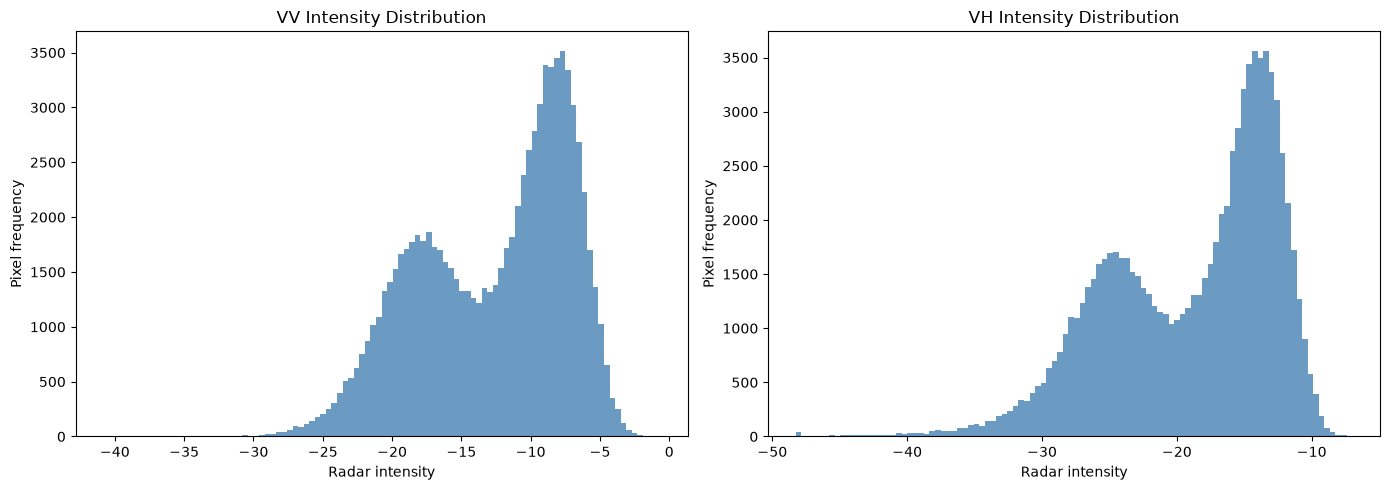

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for channel, name in enumerate(["VV", "VH"]):

    values = image[channel][valid_mask]

    axes[channel].hist(
        values,
        bins=100,
        color="steelblue",
        alpha=0.8
    )

    axes[channel].set_title(f"{name} Intensity Distribution")
    axes[channel].set_xlabel("Radar intensity")
    axes[channel].set_ylabel("Pixel frequency")

plt.tight_layout()
plt.show()

In [9]:
rng = np.random.default_rng(42)

channel_samples = [[], []]

for sample_id in tqdm(train_df["sample_id"]):

    image_path = IMAGE_DIR / f"{sample_id}_S1Hand.tif"
    mask_path = MASK_DIR / f"{sample_id}_LabelHand.tif"

    with rasterio.open(image_path) as src:
        img = src.read().astype(np.float32)

        input_valid = (
            (src.read_masks() > 0).all(axis=0)
            & np.isfinite(img).all(axis=0)
        )

    with rasterio.open(mask_path) as src:
        target = src.read(1)

    valid = (
        np.isin(target, [0, 1])
        & input_valid
    )

    values = img[:, valid]

    if values.shape[1] == 0:
        continue

    indices = rng.choice(
        values.shape[1],
        size=min(5000, values.shape[1]),
        replace=False
    )

    for channel in range(2):
        channel_samples[channel].append(
            values[channel, indices]
        )

vv_values = np.concatenate(channel_samples[0])
vh_values = np.concatenate(channel_samples[1])

print("VV sampled pixels:", len(vv_values))
print("VH sampled pixels:", len(vh_values))

  0%|          | 0/340 [00:00<?, ?it/s]

VV sampled pixels: 1666892
VH sampled pixels: 1666892


In [6]:
statistics = []

for name, values in [
    ("VV", vv_values),
    ("VH", vh_values)
]:

    statistics.append({
        "channel": name,
        "min": float(values.min()),
        "max": float(values.max()),
        "mean": float(values.mean()),
        "std": float(values.std()),
        "p1": float(np.percentile(values, 1)),
        "p99": float(np.percentile(values, 99))
    })

stats_df = pd.DataFrame(statistics)

stats_df

,channel,min,max,mean,std,p1,p99
0,VV,-71.061768,20.583443,-10.262988,3.897098,-23.311842,-2.500904
1,VH,-78.150711,10.780976,-16.995146,4.469136,-32.127178,-9.392356


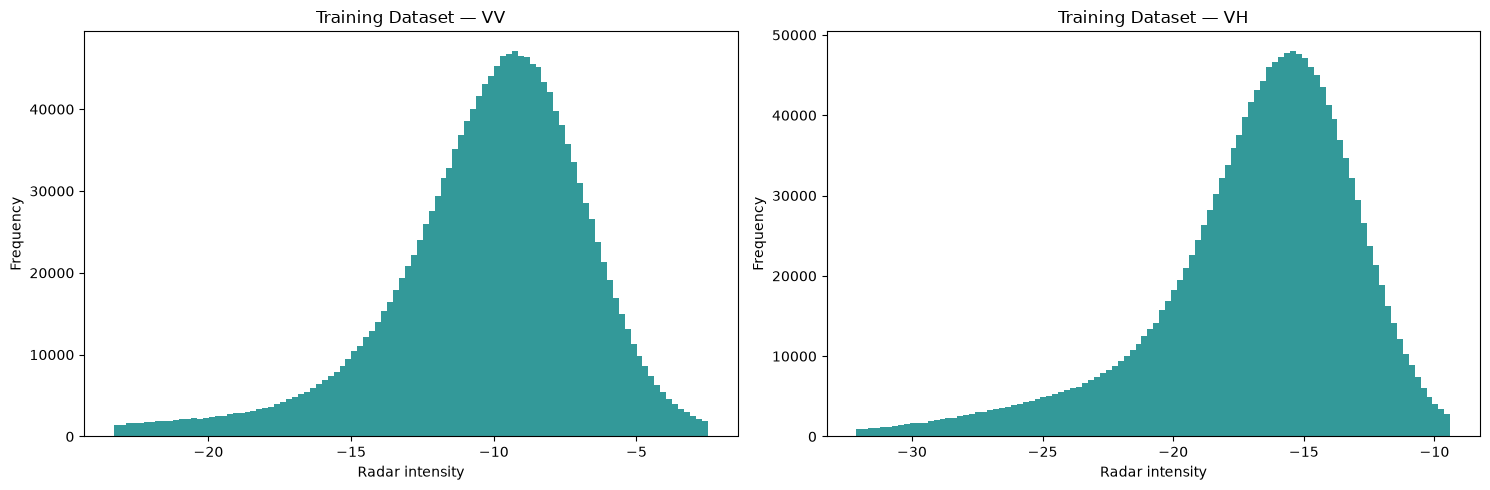

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, name, values in zip(
    axes,
    ["VV", "VH"],
    [vv_values, vh_values]
):

    p1, p99 = np.percentile(values, [1, 99])

    ax.hist(
        values,
        bins=100,
        range=(p1, p99),
        color="teal",
        alpha=0.8
    )

    ax.set_title(f"Training Dataset — {name}")
    ax.set_xlabel("Radar intensity")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [11]:
normalization_stats = {}

for name, values in [
    ("VV", vv_values),
    ("VH", vh_values)
]:

    p1, p99 = np.percentile(values, [1, 99])

    clipped = np.clip(values, p1, p99)

    normalization_stats[name] = {
        "clip_min": float(p1),
        "clip_max": float(p99),
        "mean": float(clipped.mean()),
        "std": float(clipped.std())
    }

pd.DataFrame(normalization_stats).T

,clip_min,clip_max,mean,std
VV,-23.311841,-2.500904,-10.262364,3.741768
VH,-32.127179,-9.392356,-16.962837,4.201249


In [12]:
preprocessing_config = {
    "preprocessing": {
        "method": "percentile_zscore",
        "fit_split": "geographical/train",
        "clip_percentiles": [1, 99],
        "sampling_seed": 42,
        "max_pixels_per_image": 5000,
        "epsilon": 1e-8,
        "invalid_fill_value": 0.0,
        "ignore_index": -1,
        "channels": normalization_stats
    }
}

output_path = (
    BASE_DIR / "configs" / "preprocessing.yaml"
)

with open(output_path, "w", encoding="utf-8") as file:
    yaml.safe_dump(
        preprocessing_config,
        file,
        sort_keys=False
    )

print("Configuration saved:", output_path)

Configuration saved: D:\FloodVision-AI\ml\configs\preprocessing.yaml


In [13]:
from floodvision.preprocessing.sar import (
    read_sar_image,
    read_target_mask
)

from floodvision.preprocessing.normalization import (
    SARNormalizer
)

In [14]:
sample_id = train_df.iloc[0]["sample_id"]

image_path = IMAGE_DIR / f"{sample_id}_S1Hand.tif"
mask_path = MASK_DIR / f"{sample_id}_LabelHand.tif"

raw_image, input_valid, metadata = read_sar_image(
    image_path
)

target = read_target_mask(mask_path)

normalizer = SARNormalizer(
    BASE_DIR / "configs" / "preprocessing.yaml"
)

processed_image = normalizer(
    raw_image,
    input_valid
)

# Ignore targets where input data is invalid
target[~input_valid] = -1

print("Original shape:", raw_image.shape)
print("Processed shape:", processed_image.shape)
print("Processed dtype:", processed_image.dtype)

print("NaN values:", np.isnan(processed_image).sum())
print("Inf values:", np.isinf(processed_image).sum())

print("Minimum:", processed_image.min())
print("Maximum:", processed_image.max())

print("Target labels:", np.unique(target))

assert np.isfinite(processed_image).all()
assert np.all(processed_image[:, ~input_valid] == 0)

Original shape: (2, 512, 512)
Processed shape: (2, 512, 512)
Processed dtype: float32
NaN values: 0
Inf values: 0
Minimum: -3.6094842
Maximum: 2.0742764
Target labels: [-1.  0.  1.]


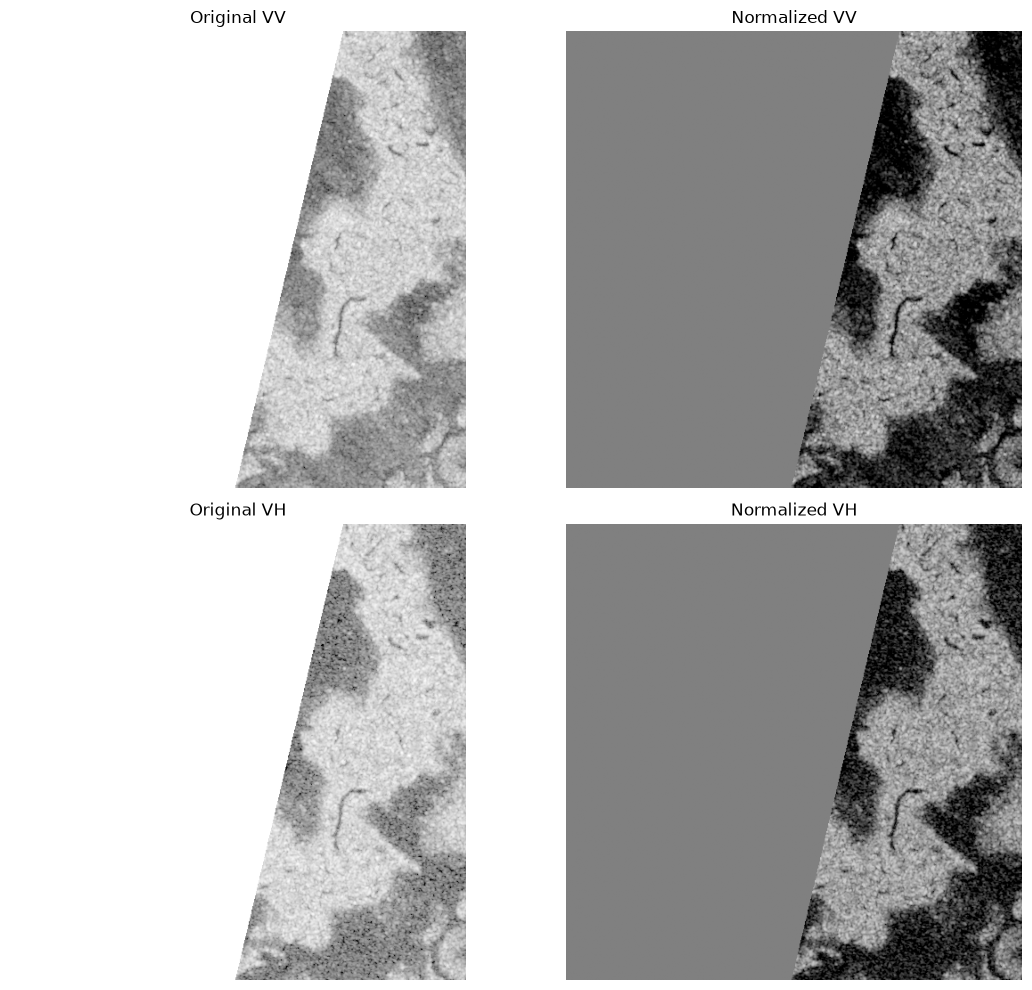

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for index, name in enumerate(["VV", "VH"]):

    axes[index, 0].imshow(
        np.where(input_valid, raw_image[index], np.nan),
        cmap="gray"
    )

    axes[index, 0].set_title(f"Original {name}")

    axes[index, 1].imshow(
        processed_image[index],
        cmap="gray",
        vmin=-3,
        vmax=3
    )

    axes[index, 1].set_title(f"Normalized {name}")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()